<a href="https://colab.research.google.com/github/kaixing189/MSSP607/blob/main/Week_10_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 Network Analysis — Improved Version

**Course:** MSSP607  
**Student:** Kai Xing

## AI code-improvement recommendations

The original notebook is useful for learning NetworkX, but the code can be improved in several ways:

1. **Remove fixed Google Drive paths.** A notebook is easier to share and reproduce when it does not depend on one person's `/content/drive/...` folder.
2. **Remove unused imports.** The network examples only need a small set of libraries.
3. **Use an explicit random seed.** Python's `hash()` can vary between sessions, so a fixed integer seed is more reproducible.
4. **Pass the seed directly to layout algorithms.** This makes network positions stable across runs.
5. **Avoid repeated setup code.** Imports and plotting configuration should appear once.
6. **Use built-in graph attributes when available.** The Karate Club graph already contains club membership information, so it is safer than maintaining a separate hard-coded list.
7. **Use helper functions for repeated logic.** This makes the notebook easier to read and reuse.
8. **Handle the external GEXF file more robustly.** The original notebook reads `klas12b-net-1.gexf` using only a bare filename. The improved version checks common notebook locations and gives a clear error message if the file is missing.
9. **Add descriptive output and comments.** Small summaries make it easier to understand what each code cell is demonstrating.
10. **End with verification checks.** Assertions confirm that the main graphs and attributes were created correctly.

> **Data-file note:** This improved notebook uses the supplied `klas12b-net-1.gexf` file for the directed-network section. Submit that data file together with the notebook.


## 1. Setup

Only the libraries used in the notebook are imported. A fixed seed is used for reproducible layouts.


In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# GitHub repository information
owner = 'kaixing189'
repository = 'MSSP607'

repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

# Clone repository if it is not already in Colab
if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

# Change current working directory to the repository
os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("\nFiles in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Repository already exists. Using the existing copy.
Current directory: /content/MSSP607

Files in repository:
Adding_File_Structure.py
Assignments/.gitkeep
Assignments/Academic_Performance_Analysis_Colab.ipynb
Assignments/CaseStudy2_InternetSales_Analysis.ipynb
Assignments/Case_Study_Report.docx
Assignments/Case_Study_Report.pdf
Case_Study_1_Academic_Performance.ipynb
InternetSales (3).csv
PARTICIPATION_ACTIVITY_Week_2.ipynb
Participation_Activity_Week1_Exercises.ipynb
Participation_Activity_Week1_Exercises_(2).ipynb
Participation_Activity_Week_3_assignment (1).ipynb
Participation_Activity_Week_3_assignment_(1)_(1).ipynb
README.md
Week1_Introduction_To_Data_Analysis.ipynb
Week8_Participation_Activity_Final.ipynb
Week_05_Participation_Activity.ipynbb.ipynb
Week_1_Introduction_To_Data_Analysis (1).ipynb
WeeklyModules/.gitkeep
WeeklyModules/Week01/.gitkeep
WeeklyModules/Week01/Participation_Activity_Week1_Exercises_(3).ipynb
WeeklyModules/Week02/.gitkeep
WeeklyModules/Week02/PARTICIPATION

In [3]:
import random
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

SEED = 607

random.seed(SEED)
np.random.seed(SEED)

plt.rcParams.update({
    "figure.figsize": (7.5, 7.5),
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.top": False,
    "axes.spines.bottom": False,
})

print("NetworkX version:", nx.__version__)
print("Random seed:", SEED)


NetworkX version: 3.7
Random seed: 607


## 2. Creating a simple undirected network

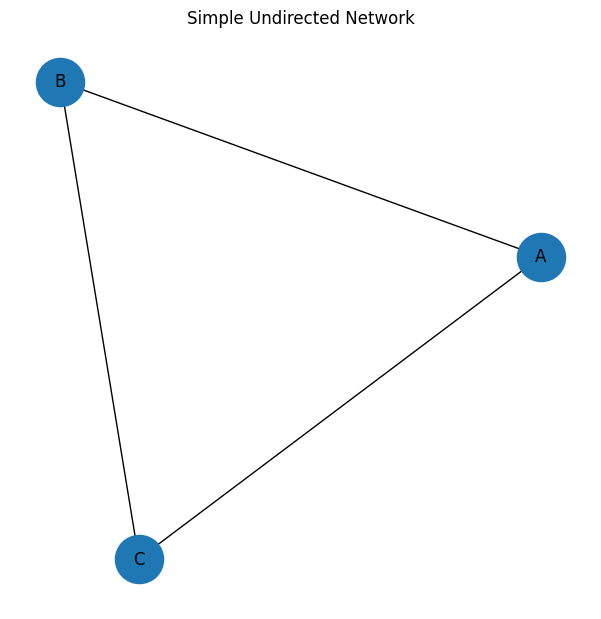

Nodes: ['A', 'B', 'C']
Edges: [('A', 'B'), ('A', 'C'), ('B', 'C')]


In [4]:
G_simple = nx.Graph()

G_simple.add_nodes_from(["A", "B", "C"])
G_simple.add_edges_from([
    ("A", "B"),
    ("B", "C"),
    ("A", "C"),
])

simple_pos = nx.spring_layout(G_simple, seed=SEED)

nx.draw_networkx(
    G_simple,
    pos=simple_pos,
    node_size=1200,
    font_size=12,
)
plt.title("Simple Undirected Network")
plt.axis("off")
plt.show()

print("Nodes:", list(G_simple.nodes))
print("Edges:", list(G_simple.edges))


Add two more nodes through new edges. NetworkX automatically creates nodes `D` and `E` when the edges are added.


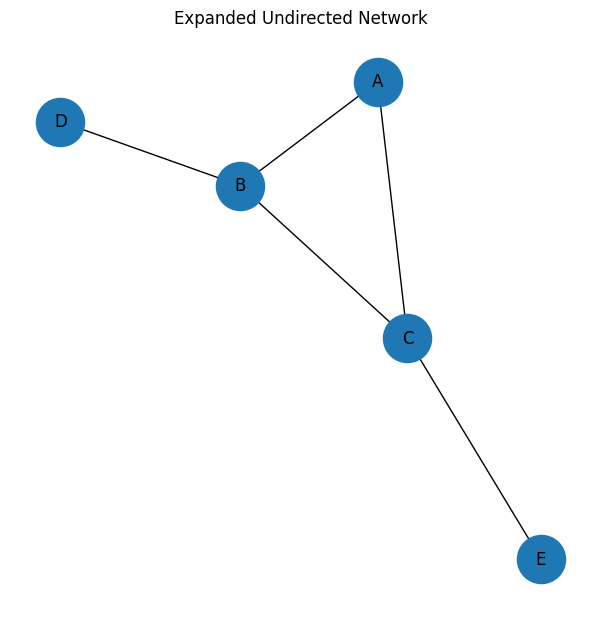

Number of nodes: 5
Number of edges: 5


In [5]:
G_simple.add_edges_from([
    ("B", "D"),
    ("C", "E"),
])

simple_pos = nx.spring_layout(G_simple, seed=SEED)

nx.draw_networkx(
    G_simple,
    pos=simple_pos,
    node_size=1200,
    font_size=12,
)
plt.title("Expanded Undirected Network")
plt.axis("off")
plt.show()

print("Number of nodes:", G_simple.number_of_nodes())
print("Number of edges:", G_simple.number_of_edges())


## 3. The Graph class: Zachary's Karate Club network

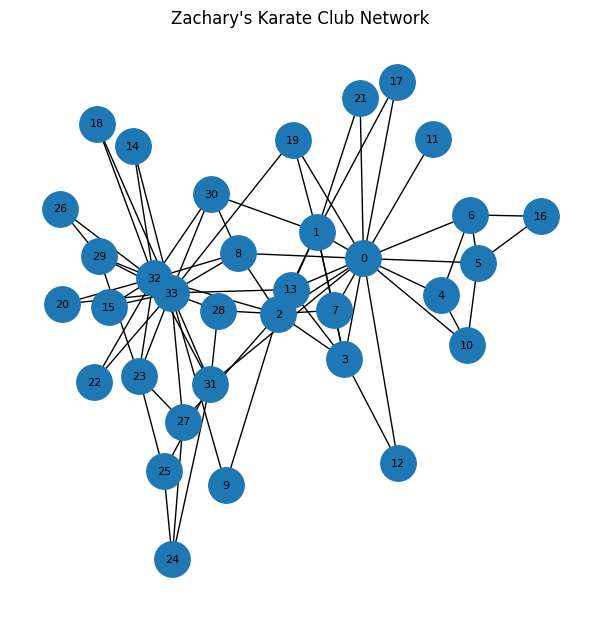

Nodes: 34
Edges: 78


In [6]:
G = nx.karate_club_graph()

karate_pos = nx.spring_layout(
    G,
    k=0.30,
    seed=SEED,
)

nx.draw_networkx(
    G,
    pos=karate_pos,
    node_size=650,
    font_size=8,
)
plt.title("Zachary's Karate Club Network")
plt.axis("off")
plt.show()

print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")


### Inspect nodes and edges

In [7]:
print("First 10 nodes:")
print(list(G.nodes)[:10])

print("\nFirst 10 edges:")
print(list(G.edges)[:10])


First 10 nodes:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

First 10 edges:
[(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 10), (0, 11)]


### Checking for nodes

In [8]:
mr_hi = 0
wild_goose = 1337

print(f"Is node {mr_hi} in the graph? {mr_hi in G}")
print(f"G.has_node({mr_hi}): {G.has_node(mr_hi)}")

print(f"\nIs node {wild_goose} in the graph? {wild_goose in G}")
print(f"G.has_node({wild_goose}): {G.has_node(wild_goose)}")


Is node 0 in the graph? True
G.has_node(0): True

Is node 1337 in the graph? False
G.has_node(1337): False


### Finding neighbors and checking edges

In [9]:
member_id = 1
john_a = 33

print("Neighbors of node 0:")
print(list(G.neighbors(mr_hi)))

print(f"\nDoes edge ({mr_hi}, {member_id}) exist? {G.has_edge(mr_hi, member_id)}")
print(f"Does edge ({mr_hi}, {john_a}) exist? {G.has_edge(mr_hi, john_a)}")


Neighbors of node 0:
[1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 17, 19, 21, 31]

Does edge (0, 1) exist? True
Does edge (0, 33) exist? False


## 4. Node attributes

The built-in Karate Club graph already includes a `club` attribute. Instead of maintaining a separate hard-coded membership list, the code maps the existing labels to numeric groups.


In [10]:
club_map = {
    "Mr. Hi": 0,
    "Officer": 1,
}

for node_id, attributes in G.nodes(data=True):
    attributes["club_id"] = club_map[attributes["club"]]

print("Node 0 attributes:", G.nodes[0])
print("Node 33 attributes:", G.nodes[33])


Node 0 attributes: {'club': 'Mr. Hi', 'club_id': 0}
Node 33 attributes: {'club': 'Officer', 'club_id': 1}


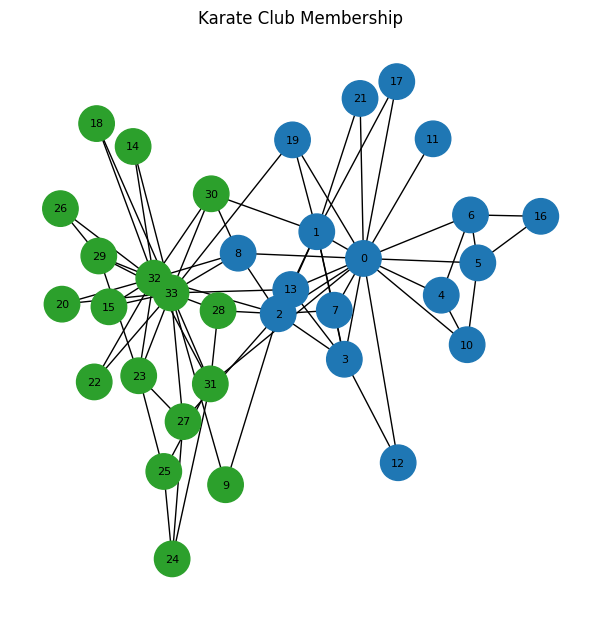

In [11]:
node_color = [
    "tab:blue" if G.nodes[node]["club_id"] == 0 else "tab:green"
    for node in G.nodes
]

nx.draw_networkx(
    G,
    pos=karate_pos,
    node_color=node_color,
    node_size=650,
    font_size=8,
)
plt.title("Karate Club Membership")
plt.axis("off")
plt.show()


## 5. Edge attributes: internal versus external ties

An internal edge connects two members of the same club. An external edge connects members of different clubs.


In [12]:
for v, w in G.edges:
    G.edges[v, w]["internal"] = (
        G.nodes[v]["club_id"] == G.nodes[w]["club_id"]
    )

internal_edges = [
    edge for edge in G.edges
    if G.edges[edge]["internal"]
]

external_edges = [
    edge for edge in G.edges
    if not G.edges[edge]["internal"]
]

print("Internal edges:", len(internal_edges))
print("External edges:", len(external_edges))


Internal edges: 67
External edges: 11


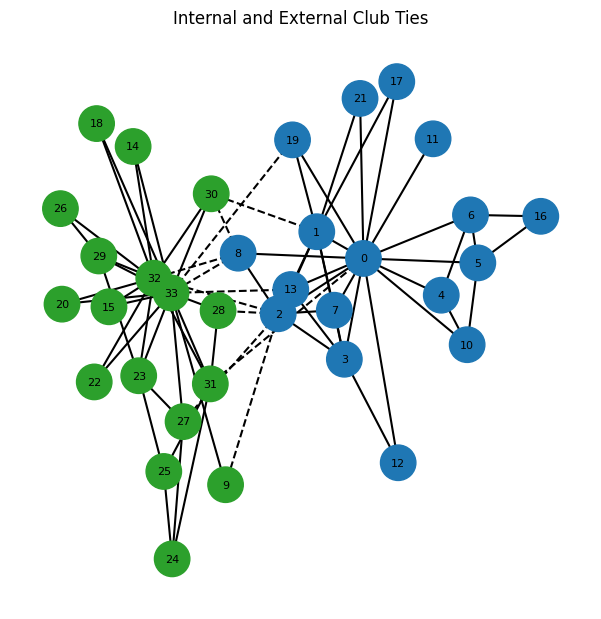

In [13]:
nx.draw_networkx_nodes(
    G,
    pos=karate_pos,
    node_color=node_color,
    node_size=650,
)

nx.draw_networkx_labels(
    G,
    pos=karate_pos,
    font_size=8,
)

nx.draw_networkx_edges(
    G,
    pos=karate_pos,
    edgelist=internal_edges,
    width=1.5,
)

nx.draw_networkx_edges(
    G,
    pos=karate_pos,
    edgelist=external_edges,
    style="dashed",
    width=1.5,
)

plt.title("Internal and External Club Ties")
plt.axis("off")
plt.show()


## 6. Adding edge weights

The function below defines tie strength as one plus the number of common neighbors shared by the two endpoints of an edge.


In [14]:
def tie_strength(graph, v, w):
    """Return 1 plus the number of common neighbors of v and w."""
    v_neighbors = set(graph.neighbors(v))
    w_neighbors = set(graph.neighbors(w))
    return 1 + len(v_neighbors & w_neighbors)


for v, w in G.edges:
    G.edges[v, w]["weight"] = tie_strength(G, v, w)

edge_weights = [
    G.edges[v, w]["weight"]
    for v, w in G.edges
]

print("Minimum edge weight:", min(edge_weights))
print("Maximum edge weight:", max(edge_weights))
print("Mean edge weight:", round(np.mean(edge_weights), 2))


Minimum edge weight: 1
Maximum edge weight: 11
Mean edge weight: 2.73


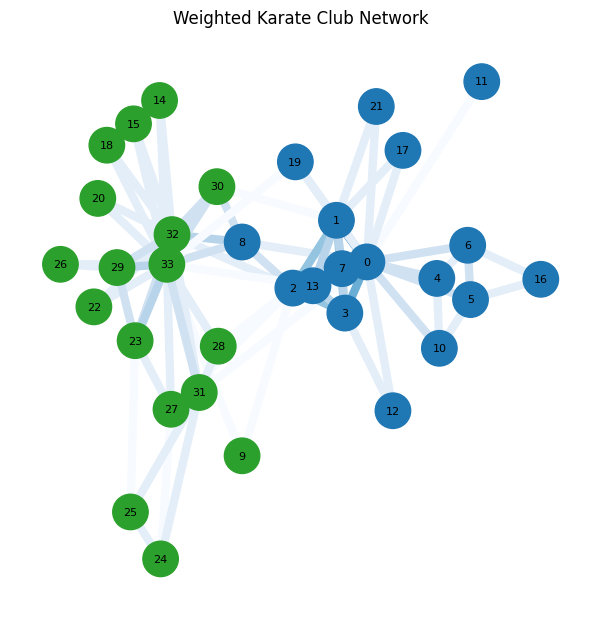

In [15]:
weighted_pos = nx.spring_layout(
    G,
    pos=karate_pos,
    k=0.30,
    weight="weight",
    seed=SEED,
)

nx.draw_networkx(
    G,
    pos=weighted_pos,
    node_color=node_color,
    node_size=650,
    font_size=8,
    width=6,
    edge_color=edge_weights,
    edge_cmap=plt.cm.Blues,
)

plt.title("Weighted Karate Club Network")
plt.axis("off")
plt.show()


## 7. The DiGraph class: when direction matters

This section uses the original class data file, **`klas12b-net-1.gexf`**.

The improved code checks several common locations instead of assuming the file is always in the current working directory. This makes the notebook easier to run in Google Colab, Jupyter, or after downloading the files from Canvas.


In [16]:
from pathlib import Path

gexf_candidates = [
    Path("klas12b-net-1.gexf"),
    Path("/content/klas12b-net-1.gexf"),
    Path("/content/MSSP607/data/klas12b-net-1.gexf"),
    Path("/mnt/data/klas12b-net-1.gexf"),
]

gexf_path = next(
    (path for path in gexf_candidates if path.exists()),
    None
)

if gexf_path is None:
    raise FileNotFoundError(
        "klas12b-net-1.gexf was not found. "
        "Upload the GEXF file to the same Colab session or place it in MSSP607/data/."
    )

student_network = nx.read_gexf(
    gexf_path,
    node_type=int
)

print("Loaded:", gexf_path)
print("Graph type:", type(student_network).__name__)
print("Directed:", student_network.is_directed())
print("Number of nodes:", student_network.number_of_nodes())
print("Number of edges:", student_network.number_of_edges())


Loaded: /content/MSSP607/data/klas12b-net-1.gexf
Graph type: DiGraph
Directed: True
Number of nodes: 26
Number of edges: 91


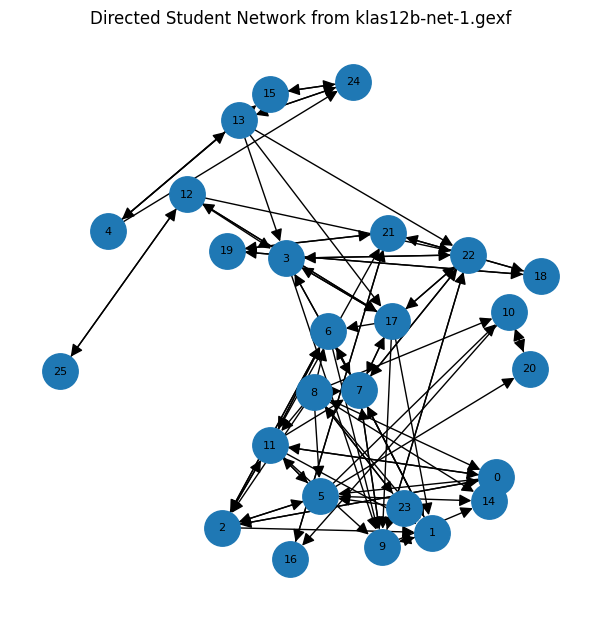

In [17]:
student_pos = nx.spring_layout(
    student_network,
    k=1.5,
    seed=SEED,
)

nx.draw_networkx(
    student_network,
    pos=student_pos,
    node_size=650,
    font_size=8,
    arrowsize=18,
)

plt.title("Directed Student Network from klas12b-net-1.gexf")
plt.axis("off")
plt.show()


### Neighbors, successors, and predecessors

In a directed graph, `successors()` returns nodes reached by outgoing edges, while `predecessors()` returns nodes that point into the selected node.


In [18]:
target_node = 0

print(
    f"Neighbors of node {target_node}:",
    list(student_network.neighbors(target_node))
)

print(
    f"Successors of node {target_node}:",
    list(student_network.successors(target_node))
)

print(
    f"Predecessors of node {target_node}:",
    list(student_network.predecessors(target_node))
)


Neighbors of node 0: [2, 5, 11]
Successors of node 0: [2, 5, 11]
Predecessors of node 0: [2, 11, 8]


### Convert the directed network to undirected versions

- `to_undirected()` keeps a connection when either direction exists.
- `to_undirected(reciprocal=True)` keeps only pairs where both directed edges exist.


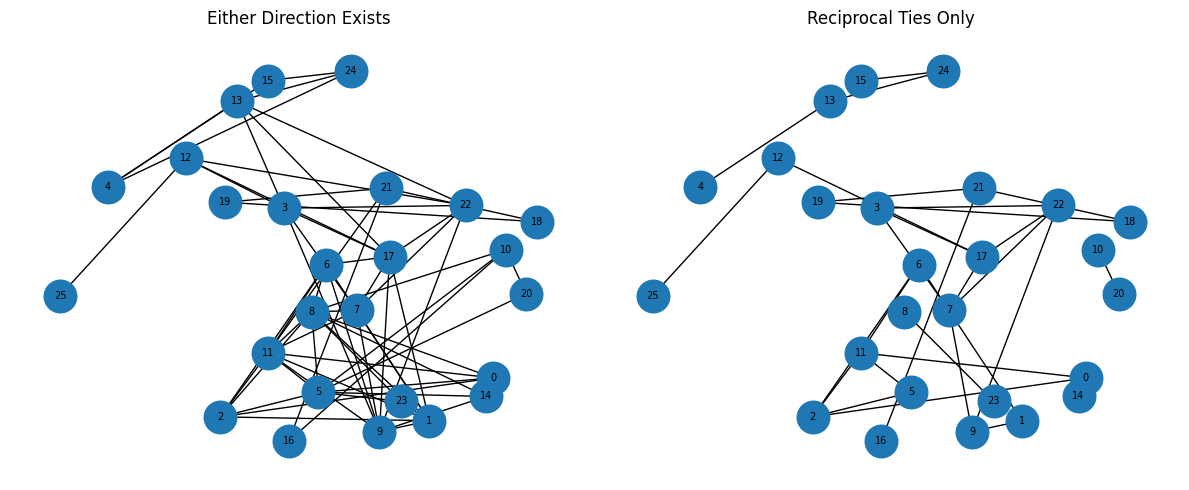

Either-direction edges: 63
Reciprocal edges: 28


In [19]:
student_either = student_network.to_undirected()
student_both = student_network.to_undirected(reciprocal=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

nx.draw_networkx(
    student_either,
    pos=student_pos,
    ax=axes[0],
    node_size=550,
    font_size=7,
)
axes[0].set_title("Either Direction Exists")
axes[0].axis("off")

nx.draw_networkx(
    student_both,
    pos=student_pos,
    ax=axes[1],
    node_size=550,
    font_size=7,
)
axes[1].set_title("Reciprocal Ties Only")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Either-direction edges:", student_either.number_of_edges())
print("Reciprocal edges:", student_both.number_of_edges())


## 8. MultiGraph and MultiDiGraph: parallel edges

In [20]:
bridges = nx.MultiGraph()

bridges.add_edges_from([
    ("North Bank", "Kneiphof", {"bridge": "Krämerbrücke"}),
    ("North Bank", "Kneiphof", {"bridge": "Schmiedebrücke"}),
    ("North Bank", "Lomse",    {"bridge": "Holzbrücke"}),
    ("Lomse",      "Kneiphof", {"bridge": "Dombrücke"}),
    ("South Bank", "Kneiphof", {"bridge": "Grüne Brücke"}),
    ("South Bank", "Kneiphof", {"bridge": "Köttelbrücke"}),
    ("South Bank", "Lomse",    {"bridge": "Hohe Brücke"}),
])

print("Number of nodes:", bridges.number_of_nodes())
print("Number of edges:", bridges.number_of_edges())
print("First edge:", list(bridges.edges(keys=True))[0])
print(
    "First North Bank–Kneiphof edge attributes:",
    bridges.edges["North Bank", "Kneiphof", 0]
)


Number of nodes: 4
Number of edges: 7
First edge: ('North Bank', 'Kneiphof', 0)
First North Bank–Kneiphof edge attributes: {'bridge': 'Krämerbrücke'}


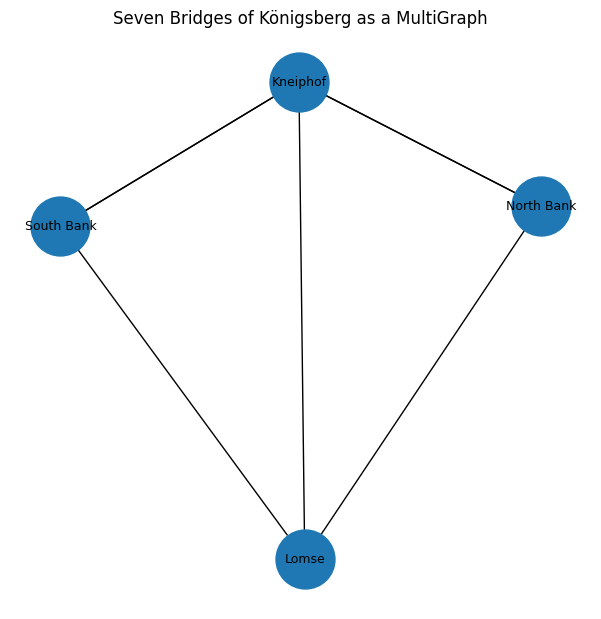

In [21]:
bridge_pos = nx.spring_layout(
    bridges,
    seed=SEED,
)

nx.draw_networkx(
    bridges,
    pos=bridge_pos,
    node_size=1800,
    font_size=9,
)

plt.title("Seven Bridges of Königsberg as a MultiGraph")
plt.axis("off")
plt.show()


## 9. Final verification

These checks confirm that the improved notebook created the expected network structures and attributes.


In [22]:
assert G_simple.number_of_nodes() == 5
assert G_simple.number_of_edges() == 5

assert G.number_of_nodes() == 34
assert G.number_of_edges() == 78
assert all("club_id" in G.nodes[node] for node in G.nodes)
assert all("internal" in G.edges[edge] for edge in G.edges)
assert all("weight" in G.edges[edge] for edge in G.edges)

assert student_network.is_directed()
assert student_network.number_of_nodes() == 26
assert student_network.number_of_edges() == 91
assert student_either.number_of_edges() == 63
assert student_both.number_of_edges() == 28

assert bridges.is_multigraph()
assert bridges.number_of_edges() == 7

print("All Week 10 network analysis checks passed successfully.")


All Week 10 network analysis checks passed successfully.
